# K-Means Clustering

![Workflow K-Means Clustering](../../img/tg2.png)

## Dokumentasi Workflow (KNIME)

Workflow di atas merupakan rancangan proses klasterisasi menggunakan algoritma K-Means yang membandingkan dua eksperimen utama: **tanpa reduksi dimensi** dan **dengan reduksi dimensi (PCA)**. Masing-masing eksperimen diuji dengan jumlah klaster (k) sebanyak 3 dan 5.

Berikut adalah penjelasan fungsi untuk setiap node yang digunakan:

1. **MySQL Connector**
   Berfungsi untuk membangun koneksi dari KNIME ke server database MySQL menggunakan kredensial (host, port, database, username, password) yang sesuai.

2. **DB Table Selector**
   Menyeleksi atau memilih tabel spesifik (beserta kolom-kolomnya melalui query SQL jika diperlukan) di dalam database MySQL yang berisi data mentah polutan.

3. **DB Reader**
   Mengeksekusi query dari DB Table Selector dan menarik (import) data mentah tersebut dari database ke dalam memori/environment KNIME agar dapat diproses pada node-node selanjutnya.
   
4. **Column Filter**
   Menyeleksi fitur-fitur yang akan digunakan dalam pemodelan. Pada kasus ini, node ini digunakan secara spesifik untuk **menghilangkan kolom id** karena kolom tersebut tidak memiliki nilai analitik untuk proses klasterisasi.

5. **PCA (Principal Component Analysis)**
   **PCA** adalah teknik reduksi dimensi yang digunakan untuk menyederhanakan kompleksitas data berdimensi tinggi (memiliki banyak atribut/kolom) sambil tetap mempertahankan informasi penting sebanyak mungkin. PCA bekerja dengan mentransformasikan fitur-fitur asli yang mungkin saling berkorelasi menjadi sekumpulan variabel baru yang tidak saling berkorelasi (independen), yang disebut **Principal Components (Komponen Utama)**.
   
   Pada eksperimen ini, PCA secara spesifik digunakan untuk mengatasi masalah *curse of dimensionality* (kutukan dimensi) akibat banyaknya jumlah fitur. Sesuai dengan keterangan pada workflow, node ini berhasil **mereduksi dimensi dari 68 fitur awal menjadi hanya 37 komponen utama**. 
   
   Penerapan PCA dalam alur K-Means sangat bermanfaat karena:
   - **Meningkatkan performa K-Means:** K-Means mengelompokkan data berdasarkan jarak (seperti jarak Euclidean). Pada dimensi yang terlalu tinggi, jarak antar semua titik cenderung menjadi sama, membuat klastering tidak efektif.
   - **Efisiensi komputasi:** Lebih sedikit dimensi berarti waktu eksekusi perhitungan akan lebih cepat.
   - **Menghilangkan Noise:** PCA membantu menyaring fitur-fitur yang tidak relevan yang berpotensi merusak hasil klaster.
   
6. **k-Means**
   Algoritma inti yang bertugas mengelompokkan data ke dalam *k* klaster. Pada workflow ini, K-Means dijalankan dalam 4 skenario berbeda:
   - Klastering dengan 3 klaster (menggunakan data asli tanpa PCA).
   - Klastering dengan 5 klaster (menggunakan data asli tanpa PCA).
   - Klastering dengan 3 klaster (menggunakan 37 komponen hasil PCA).
   - Klastering dengan 5 klaster (menggunakan 37 komponen hasil PCA).

7. **Silhouette Coefficient**
   Metrik evaluasi yang digunakan untuk mengukur seberapa baik setiap titik data dikelompokkan ke dalam klasternya sendiri dibandingkan dengan klaster lain. Nilai yang mendekati 1 menunjukkan klastering yang baik.

8. **Table View**
   Node visualisasi yang menampilkan nilai Silhouette Coefficient untuk masing-masing data dalam format tabel interaktif. Node ini juga menunjukkan ringkasan rata-rata (Mean). Berdasarkan gambar, performa terbaik didapat pada pembagian 3 klaster dengan rata-rata **Mean = 0.946**.

9. **Scatter Plot**
   Node visualisasi untuk membuat grafik pencar yang memperlihatkan persebaran titik-titik data berdasarkan klaster yang terbentuk, sehingga kita bisa melihat batas (separasi) antar klaster secara visual.

---

## Pendahuluan

Setelah tahap preprocessing dan ekstraksi fitur selesai, langkah selanjutnya dalam analisis data polutan adalah membangun kelompok atau klaster berdasarkan kemiripan karakteristik antar lokasi. Pada proyek ini, data yang digunakan bukan data mentah harian, tetapi data hasil ekstraksi fitur time series dari setiap lokasi/daerah. Setiap baris data mewakili satu lokasi, sedangkan kolom-kolomnya adalah fitur statistik, temporal, spektral, dan fraktal yang diperoleh dari time series polutan.

File yang menjadi dasar analisis klasterisasi adalah file hasil ekstraksi fitur yang ada di workspace, yaitu:

- `ekstraksi_fitur_co.csv`
- `ekstraksi_fitur_no2.csv`
- `ekstraksi_fitur_so2.csv`

Struktur file tersebut sudah konsisten, yaitu terdapat kolom `id`, `nama`, `daerah`, serta sejumlah fitur hasil TSFEL. Dengan demikian, setiap lokasi dapat diperlakukan sebagai satu titik data dalam ruang fitur multidimensi. Tujuan dari klasterisasi adalah mencari pola kemiripan antar lokasi berdasarkan karakteristik konsentrasi polutan yang sudah direpresentasikan dalam bentuk fitur numerik.

Misalnya, pada file `ekstraksi_fitur_co.csv`, tiap observasi mewakili satu lokasi di wilayah tertentu. Fitur seperti `calc_mean`, `calc_std`, `autocorr`, `entropy`, `hurst_exponent`, `spectral_centroid`, dan `wavelet_energy` mencerminkan profil sinyal polutan untuk lokasi tersebut. Karena jumlah fitur cukup banyak, ruang data menjadi multidimensi. K-Means merupakan algoritma yang sangat cocok untuk mengelompokkan titik-titik data tersebut secara otomatis tanpa memerlukan label kelas awal.

---

## 1. Data yang Digunakan dalam Proyek

### 1.1 Struktur Dataset

Dataset yang dipakai pada tahap klasterisasi berisi beberapa kolom utama, yaitu:

```text
id, nama, daerah, abs_energy, auc, autocorr, average_power, ... , zero_cross
```

Berikut arti masing-masing bagian:

1. `id`  
   Nomor identitas lokasi atau sampel.

2. `nama`  
   Nama individu atau lokasi yang mewakili titik pengamatan.

3. `daerah`  
   Informasi wilayah asal data, misalnya Kabupaten, Kota, Kecamatan, atau area pengamatan lainnya.

4. `abs_energy`, `auc`, `autocorr`, `average_power`, ...  
   Kolom fitur hasil ekstraksi time series. Semua kolom tersebut berisi nilai numerik hasil perhitungan TSFEL.

Karena fitur-fitur ini memiliki skala yang berbeda, maka sebelum melakukan klasterisasi perlu dilakukan standarisasi. Tanpa standarisasi, fitur yang memiliki nilai numerik sangat besar (misalnya `sum_abs_diff`, `distance`, atau `mfcc`) dapat mendominasi proses perhitungan jarak, sehingga hasil klaster menjadi bias terhadap fitur tertentu.

### 1.2 Karakteristik Data

Data pada file ekstraksi fitur biasanya memiliki karakteristik berikut:

- Tiap baris adalah satu lokasi/alamat pengamatan.
- Tiap kolom adalah satu fitur hasil ekstraksi deret waktu.
- Fitur-fitur tersebut berasal dari berbagai domain, seperti:
  - Statistical
  - Temporal
  - Spectral
  - Fractal
- Dataset bersifat numerik dan memiliki banyak dimensi.

Dengan data seperti ini, K-Means dapat mengelompokkan lokasi-lokasi yang memiliki karakteristik serupa berdasarkan pola konsentrasi polutan maupun dinamika perubahan seri waktunya.

---

## 2. Konsep K-Means Clustering

Algoritma K-Means adalah salah satu teknik clustering unsupervised learning yang paling umum dipakai dalam analisis data. Tujuan utama dari algoritma ini adalah membagi sekumpulan data ke dalam `k` kelompok sehingga titik-titik dalam satu kelompok memiliki kemiripan yang tinggi, sedangkan titik-titik antar kelompok memiliki perbedaan yang jelas.

### 2.1 Prinsip Dasar

K-Means bekerja dengan cara berikut:

1. Menentukan jumlah klaster `k` yang diinginkan.
2. Memilih `k` pusat klaster awal secara acak atau menggunakan inisialisasi tertentu.
3. Menghitung jarak setiap data ke semua pusat klaster.
4. Menetapkan setiap data ke klaster dengan jarak terdekat.
5. Memperbarui posisi pusat klaster berdasarkan rata-rata data yang masuk ke dalamnya.
6. Ulangi langkah 3-5 sampai posisi pusat klaster tidak berubah secara signifikan atau sampai iterasi maksimum tercapai.

Secara matematis, K-Means meminimalkan fungsi objektif berikut:

$$
J = \sum_{i=1}^{n} \sum_{j=1}^{k} w_{ij} \|x_i - c_j\|^2
$$

dengan:

- $x_i$ = data ke-$i$
- $c_j$ = pusat klaster ke-$j$
- $w_{ij}$ = indikator apakah data $x_i$ termasuk dalam klaster $j$
- $\|x_i - c_j\|^2$ = jarak Euclidean kuadrat antara data dan pusat klaster

### 2.2 Mengapa K-Means Cocok untuk Data Polutan?

K-Means sangat cocok untuk data hasil ekstraksi fitur polutan karena:

- Data telah diubah menjadi variabel numerik yang siap diproses.
- Lokasi dapat dipandang sebagai titik dalam ruang fitur.
- Beberapa wilayah kemungkinan memiliki profil polutan yang serupa, misalnya wilayah perkotaan, pesisir, atau daerah industri.
- K-Means menghasilkan pembagian yang mudah diinterpretasi dan divisualisasikan.

Namun, K-Means juga memiliki beberapa keterbatasan, yaitu:

- Memerlukan penentuan jumlah klaster `k` secara eksplisit.
- Sensitif terhadap nilai awal pusat klaster.
- Bergantung pada skala fitur.
- Kurang efektif jika data memiliki outlier atau struktur non-linear yang kompleks.

Karena itu, sebelum clustering dilakukan, data perlu di-standardisasi dan evaluasi seperti silhouette coefficient juga sangat disarankan.

---

## 3. Persiapan Data untuk K-Means

### 3.1 Pemilihan Dataset

Pada proyek ini, analisis clustering dilakukan menggunakan dataset hasil ekstraksi fitur dari polutan. Karena setiap file berisi banyak fitur yang dapat membentuk ruang dimensi yang sangat tinggi, seorang peneliti sebaiknya memilih satu polutan atau satu subset fitur sesuai tujuan analisis.

Untuk kasus ini, dataset yang paling relevan adalah `ekstraksi_fitur_co.csv`, karena file tersebut berisi data yang siap dipakai untuk klasifikasi karakteristik lokasi berdasarkan pola CO. File lain seperti `ekstraksi_fitur_no2.csv` dan `ekstraksi_fitur_so2.csv` juga dapat diproses dengan prinsip yang sama.

### 3.2 Memilih Kolom Fitur

Semua kolom yang berisi fitur numerik dipakai sebagai input clustering. Kolom yang bersifat identitas seperti `id`, `nama`, dan `daerah` tidak termasuk ke dalam proses clustering karena:

- bukan variabel numerik yang membentuk pola statistik,
- tidak menggambarkan karakteristik sinyal,
- dapat mengacaukan komputasi jarak jika ikut masuk.

Oleh karena itu, langkah penting dalam persiapan data adalah:

```python
feature_columns = [
    'abs_energy', 'auc', 'autocorr', 'average_power', 'calc_centroid',
    'calc_max', 'calc_mean', 'calc_median', 'calc_min', 'calc_std',
    'calc_var', 'dfa', 'distance', 'ecdf', 'ecdf_percentile',
    'ecdf_percentile_count', 'ecdf_slope', 'entropy', 'fundamental_frequency',
    'higuchi_fractal_dimension', 'hist_mode', 'human_range_energy',
    'hurst_exponent', 'interq_range', 'kurtosis', 'lempel_ziv', 'lpcc',
    'max_frequency', 'max_power_spectrum', 'maximum_fractal_length',
    'mean_abs_deviation', 'mean_abs_diff', 'mean_diff', 'median_abs_deviation',
    'median_abs_diff', 'median_diff', 'median_frequency', 'mfcc', 'mse',
    'negative_turning', 'neighbourhood_peaks', 'petrosian_fractal_dimension',
    'pk_pk_distance', 'positive_turning', 'power_bandwidth', 'rms', 'skewness',
    'slope', 'spectral_centroid', 'spectral_decrease', 'spectral_distance',
    'spectral_entropy', 'spectral_kurtosis', 'spectral_positive_turning',
    'spectral_roll_off', 'spectral_roll_on', 'spectral_skewness',
    'spectral_slope', 'spectral_spread', 'spectral_variation',
    'spectrogram_mean_coeff', 'sum_abs_diff', 'wavelet_abs_mean',
    'wavelet_energy', 'wavelet_entropy', 'wavelet_std', 'wavelet_var', 'zero_cross'
]
```

Kolom identitas seperti `id`, `nama`, dan `daerah` dipisahkan agar tidak ikut dalam proses K-Means.

### 3.3 Penanganan Missing Value

Sebelum dilakukan clustering, setiap nilai NaN atau data yang hilang harus ditangani. Ada beberapa cara yang umum dipakai:

- `dropna()` untuk membuang baris yang mengandung NaN
- `fillna()` dengan nilai rata-rata atau median
- `SimpleImputer` dari scikit-learn

Untuk data ekstraksi fitur hasil TSFEL, biasanya tidak banyak missing value karena data sudah melalui preprocessing sebelumnya. Namun, tetap disarankan untuk memvalidasi nilai NaN sebelum clustering.

---

## 4. Standarisasi Fitur (Scaling)

### 4.1 Mengapa Standarisasi Diperlukan?

Fitur dalam dataset ekstraksi fitur memiliki skala yang sangat berbeda. Misalnya:

- `calc_mean` bernilai sekitar $10^{-5}$
- `distance` dapat bernilai ratusan
- `mse` bisa berada pada skala dengan rentang yang berbeda pula

Jika semua fitur masuk langsung ke K-Means tanpa scaling, maka fitur dengan rentang besar akan mendominasi perhitungan jarak. Akibatnya, hasil klaster menjadi tidak adil. Oleh karena itu, sebelum clustering, dilakukan proses standardisasi.

### 4.2 StandardScaler

`StandardScaler` mentransformasikan setiap fitur menjadi:

$$
Z = \frac{x - \mu}{\sigma}
$$

Dengan demikian, setiap fitur memiliki rata-rata 0 dan simpangan baku 1. Ini sangat penting karena K-Means menggunakan jarak Euclidean, yang sangat sensitif terhadap skala variabel.

Karena data hasil TSFEL banyak memiliki satuan dan magnitude yang berbeda, standarisasi merupakan langkah yang tidak bisa diabaikan.

---

## 5. Metode PCA (Principal Component Analysis)

### 5.1 Apa Itu PCA?

PCA adalah teknik reduksi dimensi yang bertujuan untuk mengubah variabel yang saling berkorelasi menjadi komponen utama baru yang tidak saling berkorelasi. Ide dasarnya adalah mengekstraksi arah variasi terbesar dalam data, lalu menyimpannya dalam komponen utama.

Jika kita memiliki 68 fitur, PCA dapat menggabungkan informasi yang saling berkorelasi menjadi komponen utama yang lebih sedikit tetapi masih mampu menjelaskan sebagian besar variasi data. Dalam workflow yang umum, PCA dimanfaatkan untuk menurunkan dimensi dari 68 fitur menjadi sekitar 37 komponen.

### 5.2 Mengapa PCA Dipakai pada K-Means?

Penggunaan PCA pada klasterisasi bertujuan untuk:

- mengurangi dimensi data,
- meningkatkan efisiensi komputasi,
- menurunkan noise yang tidak relevan,
- menjaga agar K-Means tidak dipengaruhi oleh dimensi yang terlalu tinggi.

Pada ruang dimensi tinggi, K-Means cenderung mengalami masalah yang disebut *curse of dimensionality*, yaitu jarak antar titik menjadi terlalu serupa. PCA membantu memastikan bahwa struktur data tetap terjaga sementara dimensi dapat dikurangi.

### 5.3 Keuntungan dan Kelemahan PCA

Keuntungan:

- Data lebih ringkas.
- Waktu komputasi lebih cepat.
- Sering memperbaiki hasil klaster ketika adanya banyak fitur yang redundan.

Kelemahan:

- Informasi penting bisa hilang jika komponen utama yang dipilih terlalu sedikit.
- Interpretasi langsung terhadap komponen utama tidak selalu mudah.
- PCA bisa membuang variasi kecil yang mungkin justru sangat relevan dalam konteks tertentu.

Karena itu, dalam analisis ini, pengujian dilakukan dengan dua skenario:

1. K-Means tanpa PCA
2. K-Means dengan PCA

Setiap skenario kemudian diuji untuk dua nilai `k`, yaitu 3 dan 5.

---

## 6. Workflow K-Means pada Dataset Saya

Dalam konteks proyek ini, workflow analisis yang dilakukan adalah:

1. Membaca dataset hasil ekstraksi fitur
2. Menghapus kolom non-fitur (`id`, `nama`, `daerah`)
3. Mengkonversi semua kolom menjadi numerik
4. Menghapus atau mengisi missing value
5. Melakukan standardisasi dengan `StandardScaler`
6. Opsional: mengurangi dimensi dengan `PCA`
7. Menjalankan K-Means dengan `k = 3` dan `k = 5`
8. Evaluasi hasil menggunakan `Silhouette Coefficient`
9. Menampilkan scatter plot atau visualisasi klaster

Proses ini dapat diimplementasikan dalam Python dengan library `pandas`, `scikit-learn`, dan `matplotlib`.

---

## 7. Implementasi Python K-Means pada Data Saya

### 7.1 Data Tanpa PCA, k = 3

*Tabel Silhouette Coefficient untuk k=3 tanpa PCA:*

```{image} ../../img/tbno3.png
:alt: Workflow K-Means Clustering
:width: 100%
:align: center
:class: mabot-gambar
```

*Visualisasi Scatter Plot untuk k=3 tanpa PCA:*
```{image} ../../img/scno3.png
:alt: Workflow K-Means Clustering
:width: 100%
:align: center
:class: mabot-gambar
```

Inertia: 660.2141

Jumlah data per cluster:
cluster_label
cluster_0     1
cluster_1    35
cluster_2     1
Name: count, dtype: int64


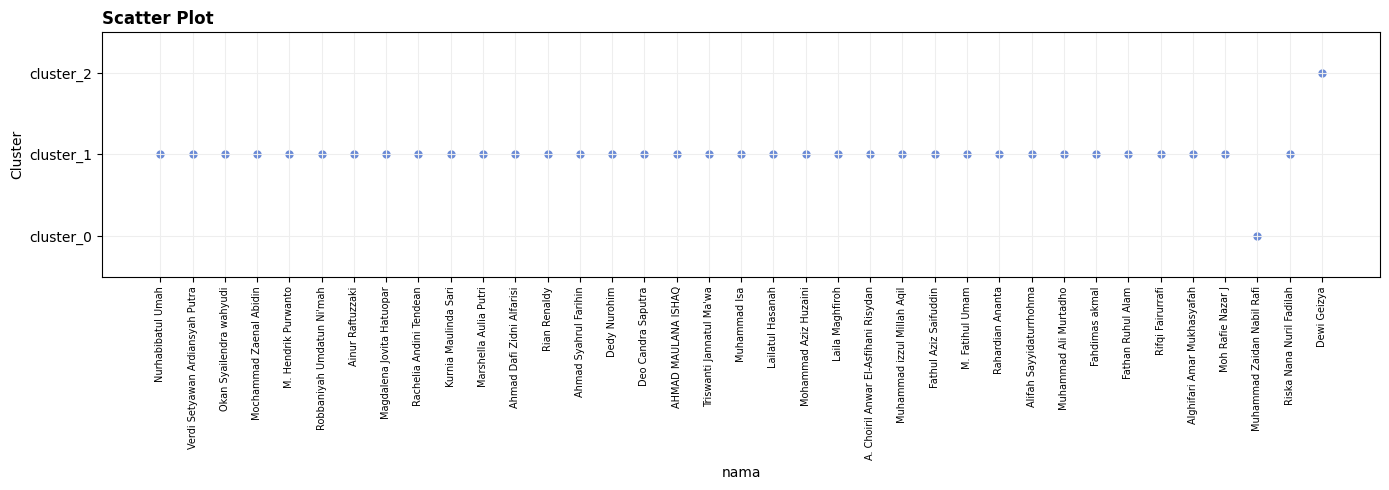

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


CSV_PATH = "../../ekstraksi_fitur_co.csv"                      
KOLOM_NAMA = "nama"                         
KOLOM_FITUR = """abs_energy auc autocorr average_power calc_centroid calc_max calc_mean
calc_median calc_min calc_std calc_var dfa distance ecdf ecdf_percentile ecdf_percentile_count
ecdf_slope entropy fundamental_frequency higuchi_fractal_dimension hist_mode human_range_energy
hurst_exponent interq_range kurtosis lempel_ziv lpcc max_frequency max_power_spectrum
maximum_fractal_length mean_abs_deviation mean_abs_diff mean_diff median_abs_deviation
median_abs_diff median_diff median_frequency mfcc mse negative_turning neighbourhood_peaks
petrosian_fractal_dimension pk_pk_distance positive_turning power_bandwidth rms skewness slope
spectral_centroid spectral_decrease spectral_distance spectral_entropy spectral_kurtosis
spectral_positive_turning spectral_roll_off spectral_roll_on spectral_skewness spectral_slope
spectral_spread spectral_variation spectrogram_mean_coeff sum_abs_diff wavelet_abs_mean
wavelet_energy wavelet_entropy wavelet_std wavelet_var zero_cross""".split()       

K = 3                                      
GUNAKAN_SCALING = True                    

# 1. Baca data
df = pd.read_csv(CSV_PATH)
data = df.dropna(subset=KOLOM_FITUR).copy()

# 2. Standarisasi (opsional)
if GUNAKAN_SCALING:
    X = StandardScaler().fit_transform(data[KOLOM_FITUR])
else:
    X = data[KOLOM_FITUR].values

# 3. K-Means
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
data["cluster"] = kmeans.fit_predict(X)
data["cluster_label"] = "cluster_" + data["cluster"].astype(str)

# 4. Hasil 
print(f"Inertia: {kmeans.inertia_:.4f}")
print("\nJumlah data per cluster:")
print(data["cluster_label"].value_counts().sort_index())

# 5. Scatter plot: nama (sumbu X) vs cluster (sumbu Y)
label_cluster = [f"cluster_{i}" for i in range(K)]
y = data["cluster"]
x = range(len(data))

plt.figure(figsize=(14, 5))
plt.scatter(x, y, s=25, color="#6b8bd6")
plt.xticks(x, data[KOLOM_NAMA], rotation=90, fontsize=7)
plt.yticks(range(K), label_cluster)
plt.ylim(-0.5, K - 0.5)
plt.title("Scatter Plot", loc="left", fontweight="bold")
plt.xlabel("nama")
plt.ylabel("Cluster")
plt.grid(True, color="#eeeeee")
plt.tight_layout()
plt.show()

### 7.2 Data Tanpa PCA, k = 5

*Tabel Silhouette Coefficient untuk k=5 tanpa PCA:*

```{image} ../../img/tbno5.png
:alt: Workflow K-Means Clustering
:width: 100%
:align: center
:class: mabot-gambar
```

*Visualisasi Scatter Plot untuk k=5 tanpa PCA:*
```{image} ../../img/scno5.png
:alt: Workflow K-Means Clustering
:width: 100%
:align: center
:class: mabot-gambar
```

Inertia: 413.8895

Jumlah data per cluster:
cluster_label
cluster_0    12
cluster_1     1
cluster_2     2
cluster_3     1
cluster_4    21
Name: count, dtype: int64


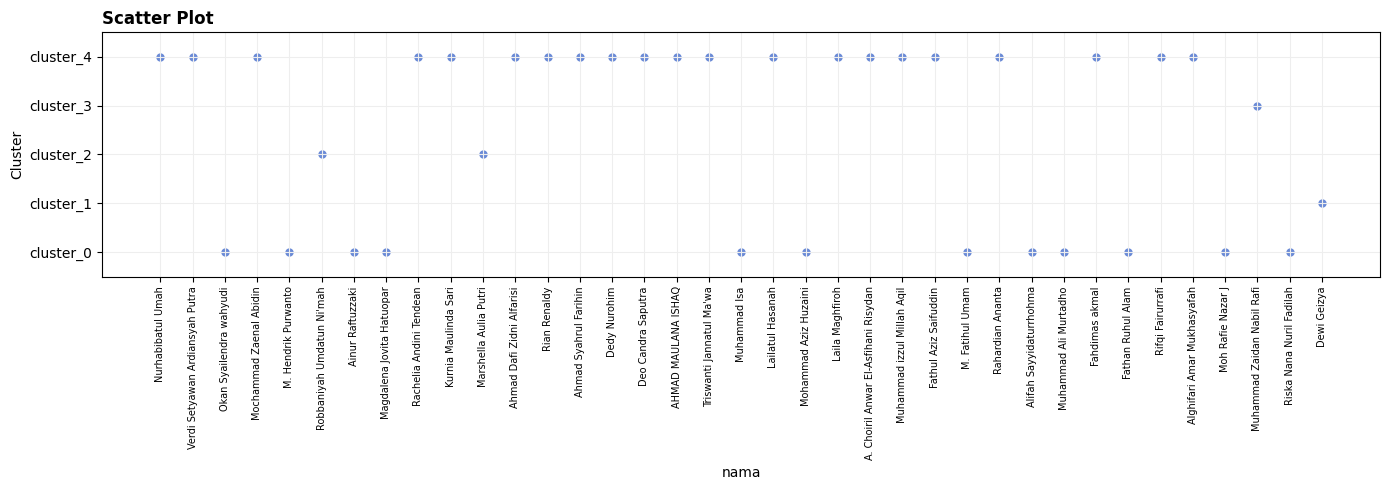

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


CSV_PATH = "../../ekstraksi_fitur_co.csv"                      
KOLOM_NAMA = "nama"                         
KOLOM_FITUR = """abs_energy auc autocorr average_power calc_centroid calc_max calc_mean
calc_median calc_min calc_std calc_var dfa distance ecdf ecdf_percentile ecdf_percentile_count
ecdf_slope entropy fundamental_frequency higuchi_fractal_dimension hist_mode human_range_energy
hurst_exponent interq_range kurtosis lempel_ziv lpcc max_frequency max_power_spectrum
maximum_fractal_length mean_abs_deviation mean_abs_diff mean_diff median_abs_deviation
median_abs_diff median_diff median_frequency mfcc mse negative_turning neighbourhood_peaks
petrosian_fractal_dimension pk_pk_distance positive_turning power_bandwidth rms skewness slope
spectral_centroid spectral_decrease spectral_distance spectral_entropy spectral_kurtosis
spectral_positive_turning spectral_roll_off spectral_roll_on spectral_skewness spectral_slope
spectral_spread spectral_variation spectrogram_mean_coeff sum_abs_diff wavelet_abs_mean
wavelet_energy wavelet_entropy wavelet_std wavelet_var zero_cross""".split()       

K = 5                                      
GUNAKAN_SCALING = True                    

# 1. Baca data
df = pd.read_csv(CSV_PATH)
data = df.dropna(subset=KOLOM_FITUR).copy()

# 2. Standarisasi
if GUNAKAN_SCALING:
    X = StandardScaler().fit_transform(data[KOLOM_FITUR])
else:
    X = data[KOLOM_FITUR].values

# 3. K-Means
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
data["cluster"] = kmeans.fit_predict(X)
data["cluster_label"] = "cluster_" + data["cluster"].astype(str)

# 4. Hasil 
print(f"Inertia: {kmeans.inertia_:.4f}")
print("\nJumlah data per cluster:")
print(data["cluster_label"].value_counts().sort_index())
x
# 5. Scatter plot: nama (sumbu X) vs cluster (sumbu Y)
label_cluster = [f"cluster_{i}" for i in range(K)]
y = data["cluster"]
x = range(len(data))

plt.figure(figsize=(14, 5))
plt.scatter(x, y, s=25, color="#6b8bd6")
plt.xticks(x, data[KOLOM_NAMA], rotation=90, fontsize=7)
plt.yticks(range(K), label_cluster)
plt.ylim(-0.5, K - 0.5)
plt.title("Scatter Plot", loc="left", fontweight="bold")
plt.xlabel("nama")
plt.ylabel("Cluster")
plt.grid(True, color="#eeeeee")
plt.tight_layout()
plt.show()

### 7.3 Data dengan PCA, k = 3

*Tabel Silhouette Coefficient untuk k=3 PCA:*

```{image} ../../img/tbpca3.png
:alt: Workflow K-Means Clustering
:width: 100%
:align: center
:class: mabot-gambar
```

*Visualisasi Scatter Plot untuk k=3 PCA:*
```{image} ../../img/scpca3.png
:alt: Workflow K-Means Clustering
:width: 100%
:align: center
:class: mabot-gambar
```

PCA: 68 fitur -> 37 dimensi

Inertia: 660.2141

Jumlah data per cluster:
cluster_label
cluster_0     1
cluster_1    35
cluster_2     1
Name: count, dtype: int64


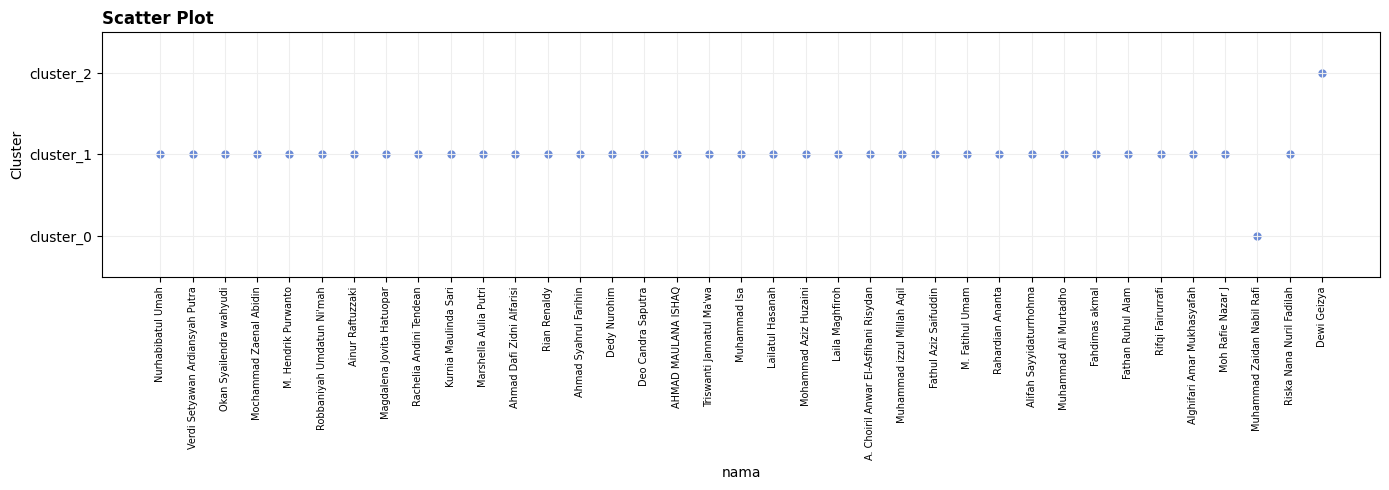

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

CSV_PATH = "../../ekstraksi_fitur_co.csv"               
KOLOM_NAMA = "nama"                               
KOLOM_FITUR = """abs_energy auc autocorr average_power calc_centroid calc_max calc_mean
calc_median calc_min calc_std calc_var dfa distance ecdf ecdf_percentile ecdf_percentile_count
ecdf_slope entropy fundamental_frequency higuchi_fractal_dimension hist_mode human_range_energy
hurst_exponent interq_range kurtosis lempel_ziv lpcc max_frequency max_power_spectrum
maximum_fractal_length mean_abs_deviation mean_abs_diff mean_diff median_abs_deviation
median_abs_diff median_diff median_frequency mfcc mse negative_turning neighbourhood_peaks
petrosian_fractal_dimension pk_pk_distance positive_turning power_bandwidth rms skewness slope
spectral_centroid spectral_decrease spectral_distance spectral_entropy spectral_kurtosis
spectral_positive_turning spectral_roll_off spectral_roll_on spectral_skewness spectral_slope
spectral_spread spectral_variation spectrogram_mean_coeff sum_abs_diff wavelet_abs_mean
wavelet_energy wavelet_entropy wavelet_std wavelet_var zero_cross""".split()
K = 3
N_DIMENSI = 37
GUNAKAN_SCALING = True

if N_DIMENSI > len(KOLOM_FITUR):
    raise ValueError(
        f"N_DIMENSI ({N_DIMENSI}) tidak boleh lebih besar dari jumlah fitur ({len(KOLOM_FITUR)})."
    )

#  Baca data
df = pd.read_csv(CSV_PATH)
data = df.dropna(subset=KOLOM_FITUR).copy()


if GUNAKAN_SCALING:
    X = StandardScaler().fit_transform(data[KOLOM_FITUR])
else:
    X = data[KOLOM_FITUR].values

# PCA
pca = PCA(n_components=N_DIMENSI, random_state=42)
X_pca = pca.fit_transform(X)

print(f"PCA: {len(KOLOM_FITUR)} fitur -> {N_DIMENSI} dimensi")

# K-Means
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
data["cluster"] = kmeans.fit_predict(X_pca)
data["cluster_label"] = "cluster_" + data["cluster"].astype(str)

# Hasil
print(f"\nInertia: {kmeans.inertia_:.4f}")
print("\nJumlah data per cluster:")
print(data["cluster_label"].value_counts().sort_index())

# Scatter plot
label_cluster = [f"cluster_{i}" for i in range(K)]
y = data["cluster"]
x = range(len(data))

plt.figure(figsize=(14, 5))
plt.scatter(x, y, s=25, color="#6b8bd6")
plt.xticks(x, data[KOLOM_NAMA], rotation=90, fontsize=7)
plt.yticks(range(K), label_cluster)
plt.ylim(-0.5, K - 0.5)
plt.title("Scatter Plot", loc="left", fontweight="bold")
plt.xlabel("nama")
plt.ylabel("Cluster")
plt.grid(True, color="#eeeeee")
plt.tight_layout()
plt.show()

### 7.4 Data dengan PCA, k = 5

*Tabel Silhouette Coefficient untuk k=5 PCA:*

```{image} ../../img/tbpca5.png
:alt: Workflow K-Means Clustering
:width: 100%
:align: center
:class: mabot-gambar
```

*Visualisasi Scatter Plot untuk k=5 PCA:*
```{image} ../../img/scpca5.png
:alt: Workflow K-Means Clustering
:width: 100%
:align: center
:class: mabot-gambar
```

PCA: 68 fitur -> 37 dimensi

Inertia: 413.8895

Jumlah data per cluster:
cluster_label
cluster_0    12
cluster_1     1
cluster_2     2
cluster_3     1
cluster_4    21
Name: count, dtype: int64


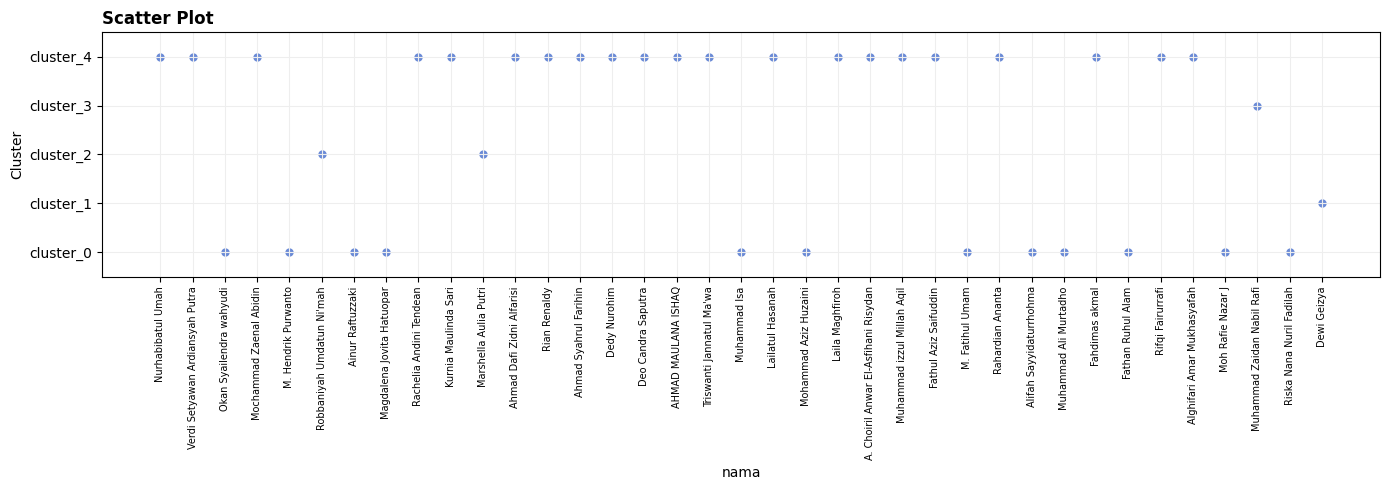

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

CSV_PATH = "../../ekstraksi_fitur_co.csv"               
KOLOM_NAMA = "nama"                               
KOLOM_FITUR = """abs_energy auc autocorr average_power calc_centroid calc_max calc_mean
calc_median calc_min calc_std calc_var dfa distance ecdf ecdf_percentile ecdf_percentile_count
ecdf_slope entropy fundamental_frequency higuchi_fractal_dimension hist_mode human_range_energy
hurst_exponent interq_range kurtosis lempel_ziv lpcc max_frequency max_power_spectrum
maximum_fractal_length mean_abs_deviation mean_abs_diff mean_diff median_abs_deviation
median_abs_diff median_diff median_frequency mfcc mse negative_turning neighbourhood_peaks
petrosian_fractal_dimension pk_pk_distance positive_turning power_bandwidth rms skewness slope
spectral_centroid spectral_decrease spectral_distance spectral_entropy spectral_kurtosis
spectral_positive_turning spectral_roll_off spectral_roll_on spectral_skewness spectral_slope
spectral_spread spectral_variation spectrogram_mean_coeff sum_abs_diff wavelet_abs_mean
wavelet_energy wavelet_entropy wavelet_std wavelet_var zero_cross""".split()
K = 5
N_DIMENSI = 37
GUNAKAN_SCALING = True

if N_DIMENSI > len(KOLOM_FITUR):
    raise ValueError(
        f"N_DIMENSI ({N_DIMENSI}) tidak boleh lebih besar dari jumlah fitur ({len(KOLOM_FITUR)})."
    )

#  Baca data
df = pd.read_csv(CSV_PATH)
data = df.dropna(subset=KOLOM_FITUR).copy()


if GUNAKAN_SCALING:
    X = StandardScaler().fit_transform(data[KOLOM_FITUR])
else:
    X = data[KOLOM_FITUR].values

# PCA
pca = PCA(n_components=N_DIMENSI, random_state=42)
X_pca = pca.fit_transform(X)

print(f"PCA: {len(KOLOM_FITUR)} fitur -> {N_DIMENSI} dimensi")

# K-Means
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
data["cluster"] = kmeans.fit_predict(X_pca)
data["cluster_label"] = "cluster_" + data["cluster"].astype(str)

# Hasil
print(f"\nInertia: {kmeans.inertia_:.4f}")
print("\nJumlah data per cluster:")
print(data["cluster_label"].value_counts().sort_index())

# Scatter plot
label_cluster = [f"cluster_{i}" for i in range(K)]
y = data["cluster"]
x = range(len(data))

plt.figure(figsize=(14, 5))
plt.scatter(x, y, s=25, color="#6b8bd6")
plt.xticks(x, data[KOLOM_NAMA], rotation=90, fontsize=7)
plt.yticks(range(K), label_cluster)
plt.ylim(-0.5, K - 0.5)
plt.title("Scatter Plot", loc="left", fontweight="bold")
plt.xlabel("nama")
plt.ylabel("Cluster")
plt.grid(True, color="#eeeeee")
plt.tight_layout()
plt.show()

---

## 8. Evaluasi Klaster dengan Silhouette Coefficient

### 8.1 Apa itu Silhouette Coefficient?

Silhouette Coefficient adalah metrik evaluasi yang digunakan untuk mengukur kualitas klaster. Nilai silhouette berkisar antara -1 hingga 1. Semakin tinggi nilai silhouette, maka klaster semakin baik.

Secara sederhana:

- Nilai dekat 1 → titik data sangat cocok dengan klasternya sendiri.
- Nilai dekat 0 → titik data berada di batas antara dua klaster.
- Nilai negatif → titik data mungkin salah ditempatkan.

### 8.2 Kenapa Silhouette Penting?

Dalam analisis clustering, tidak cukup hanya melihat pembagian klaster secara visual. Perlu ada evaluasi numerik agar keputusan mengenai jumlah klaster tidak didasarkan pada intuisi semata. Karena itu silhouette coefficient sering dipakai untuk membandingkan berbagai nilai `k`.

### 8.3 Interpretasi pada Dataset Saya

Pada dataset ekstraksi fitur polutan, proses clustering dapat dilakukan dengan beberapa pendekatan. Secara umum:

- `k = 3` biasanya lebih stabil jika data memiliki pola yang jelas dan terbagi menjadi tiga kelompok utama.
- `k = 5` dapat memberikan detail yang lebih banyak, tetapi sering kali menghasilkan klaster yang lebih kecil dan lebih overlapping.
- PCA dapat membantu mengurangi dimensi tinggi sehingga komputasi lebih efisien dan klaster bisa lebih konsisten.

Dengan kata lain, jumlah klaster yang dipilih tergantung pada struktur data. Jika nilai silhouette untuk `k = 3` lebih tinggi dibandingkan `k = 5`, maka model dengan 3 cluster lebih optimal untuk data ini.

---

## 9. Visualisasi Hasil Klaster

Visualisasi sangat penting dalam klasterisasi karena memungkinkan kita melihat pola yang terbentuk. Dalam konteks proyek ini, visualisasi yang umum dipakai adalah:

1. Scatter plot antar titik data
2. Plot pengelompokan berdasarkan indeks dataset
3. Plot dengan label cluster di sisi sumbu Y
4. Plot PCA 2D untuk melihat proyeksi klaster

### 9.1 Scatter Plot

Scatter plot membantu melihat apakah klaster terlihat terpisah atau justru tumpang tindih. Jika jarak antar klaster jelas, maka pembentukan klaster berhasil. Jika klaster saling bertumpukan, maka jumlah `k` atau penggunaan PCA mungkin perlu dipertimbangkan ulang.

### 9.2 Menafsirkan Visualisasi

Dari hasil visualisasi, hal yang perlu dilihat adalah:

- seberapa jelas pemisahan antar cluster,
- apakah ada cluster yang terlalu kecil,
- apakah ada satu cluster yang sangat dominan,
- apakah cluster yang terbentuk sejalan dengan karakteristik wilayah atau polutan.

Pada data polutan, cluster dapat mencerminkan wilayah dengan karakteristik serupa, misalnya area dengan tingkat emisi tinggi, sedang, atau rendah.

---

## 10. Keuntungan Penggunaan K-Means pada Data Polutan

Penerapan K-Means pada data ekstraksi fitur polutan memiliki beberapa manfaat, di antaranya:

1. **Mengelompokkan daerah dengan karakteristik serupa**  
   Daerah yang memiliki pola emisi atau profil deret waktu yang mirip akan masuk ke klaster yang sama.

2. **Membantu monitoring kualitas udara**  
   Dengan klaster yang terbentuk, pengelola lingkungan dapat mengetahui wilayah mana yang perlu mendapat perhatian lebih.

3. **Memudahkan pengambilan keputusan**  
   Jika suatu wilayah masuk dalam klaster dengan kondisi polusi tinggi, maka intervensi dapat difokuskan ke wilayah tersebut.

4. **Mempercepat interpretasi hasil**  
   Data yang dulunya sangat banyak dan multidimensi menjadi lebih mudah dibaca dalam bentuk kelompok.

5. **Mendukung analisis lanjutan**  
   Hasil clustering dapat menjadi dasar untuk analisis berkelanjutan seperti klasifikasi, peta wilayah, atau permodelan prediktif.

---

## 11. Keterbatasan K-Means dalam Analisis Polutan

Meskipun K-Means sangat berguna, algoritma ini juga memiliki keterbatasan dalam konteks data polutan.

### 11.1 Sensitif terhadap Nilai Awal

K-Means dapat menghasilkan hasil yang berbeda jika inisialisasi pusat klaster dilakukan secara acak. Karena itu, sering digunakan `random_state=42` untuk memastikan hasil reproduktif.

### 11.2 Sensitif terhadap Skala Fitur

Jika fitur tidak di-standardisasi, hasil klaster bisa sangat buruk. Oleh karena itu, `StandardScaler` sangat penting.

### 11.3 Kelo la Kelas Tidak Diketahui

K-Means adalah teknik unsupervised. Tidak ada label sebenarnya. Sehingga interpretasi klaster harus dilakukan dengan hati-hati, bukan semata-mata berdasarkan hasil visual.

### 11.4 Tidak Cocok untuk Data dengan Struktur Nonlinear Kompleks

Pada beberapa dataset, pola data mungkin tidak berbentuk klaster bulat. Dalam situasi seperti ini, algoritma lain seperti DBSCAN, Gaussian Mixture Model, atau hierarchical clustering bisa menjadi alternatif yang lebih cocok.

---

## 12. Kesimpulan

K-Means Clustering merupakan teknik yang tepat untuk mengelompokkan lokasi-lokasi berdasarkan karakteristik fitur polutan yang telah diekstraksi. Dalam dataset proyek ini, setiap observasi mewakili satu lokasi, sedangkan setiap fitur mewakili karakteristik sinyal polutan dari berbagai domain (statistik, temporal, spektral, dan fraktal). Karena data tersebut multidimensi dan memiliki perbedaan skala, maka langkah standarisasi dan evaluasi sangat penting sebelum clustering dilakukan.

Proses analisis yang umum dilakukan adalah:

1. membaca file hasil ekstraksi fitur,
2. memilih kolom fitur yang relevan,
3. membersihkan data,
4. melakukan scaling,
5. melakukan PCA bila diperlukan,
6. menjalankan K-Means untuk beberapa nilai `k`,
7. mengevaluasi hasil dengan silhouette coefficient,
8. menvisualisasikan dan menafsirkan klaster yang terbentuk.

Dengan pendekatan seperti ini, kita dapat memahami pola pengelompokan wilayah berdasarkan karakteristik polutan yang sebenarnya. Hasilnya tidak hanya dapat divisualisasikan, tetapi juga dapat menjadi dasar untuk pengambilan keputusan dalam pengelolaan lingkungan dan mitigasi kualitas udara.

---

## 13. Saran untuk Pengembangan Selanjutnya

Untuk pengembangan lanjutan, beberapa ide yang dapat dilakukan adalah:

- melakukan clustering untuk masing-masing polutan (`CO`, `SO2`, `NO2`) secara terpisah,
- membandingkan hasil clustering dengan dan tanpa PCA,
- mencoba nilai `k` yang lebih bervariasi, misalnya `k = 2, 3, 4, 5, 6`,
- mengevaluasi dengan silhouette score dan Davies-Bouldin Index,
- membuat peta klaster berdasarkan `daerah` untuk interpretasi spasial,
- menganalisis klaster yang terbentuk dengan melihat rata-rata fitur tiap kelompok,
- menggabungkan hasil clustering dengan data geografis untuk melihat hubungan lokasi dengan tingkat polusi.

Dengan cara ini, hasil klaster tidak hanya bersifat numerik, tetapi juga memiliki makna domain yang kuat dalam konteks kualitas udara dan wilayah studi.

---

## 14. Ringkasan Singkat

Dari uraian di atas, dapat disimpulkan bahwa K-Means Clustering merupakan teknik yang sangat relevan untuk menganalisis data ekstraksi fitur polutan pada proyek ini. Data yang sudah dimurnikan dan diekstraksi dapat dipandang sebagai titik-titik dalam ruang fitur multidimensi. Dengan bantuan standardisasi, PCA, dan evaluasi silhouette, kita dapat membentuk kelompok wilayah yang memiliki karakteristik serupa, lalu menginterpretasikan kelompok tersebut ke dalam konteks kualitas udara dan pola emisi.

Proses ini merupakan tahapan penting sebelum analisis lanjutan, seperti klasifikasi, pemetaan daerah berisiko tinggi, atau prediksi konsentrasi polutan di masa depan.